In [18]:
from src.gaussian_mixture import GaussianMixtureMAR
from src.data_generator import DataGenerator
from src.missingness_generator import MissingnessGenerator
from src.utils import true_quantile

import numpy as np
import matplotlib.pyplot as plt
import torch

from src.metrics import energy_distance

from joblib import Parallel, delayed

from scipy.stats import norm

# Estimate $p_n$

$$
\mathbb P((0,0,0)\mid x) = \frac{1}{2}
$$
$$
\mathbb P((1,0,0)\mid x) = \frac{1}{4} + \frac{1}{2}(x_1 - 0.5) * (x_2 - 0.5)
$$
$$
\mathbb P((0,1,0)\mid x) = \frac{1}{4} - \frac{1}{2}(x_1 - 0.5) * (x_2 - 0.5)
$$

- $X_1 \perp X_2 \perp X_3 \sim \text{logistic} (0,1)$

In [19]:
def example2_logistic(n=2000, kk=(1,20)):
    U = torch.rand(n, 3)
    X = torch.special.logit(U)
    mg = MissingnessGenerator(U)
    M = torch.ones_like(X, device=X.device)
    M[:,:2] = mg.example2(U[:,0], U[:, 1])
    Xtest = torch.special.logit(torch.rand(n, 3))
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = gmm.sample(n)[0]
    ed = energy_distance(Xtest, Xtilde).item()
    ds = gmm.evaluate(Xtest).item()
    return ed, ds

def example2_normal(n=2000, kk=(1,20)):
    U = torch.rand(n, 3)
    X = torch.distributions.Normal(0, 1).icdf(U)
    mg = MissingnessGenerator(U)
    M = torch.ones_like(X, device=X.device)
    M[:,:2] = mg.example2(U[:,0], U[:, 1])
    Xtest = torch.randn(n, 3) # N2(0,1)
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = gmm.sample(n)[0]
    ed = energy_distance(Xtest, Xtilde).item()
    ds = gmm.evaluate(Xtest).item()
    return ed, ds

In [20]:
n = 2000
U = torch.rand(n, 3)
X = torch.special.logit(U)
mg = MissingnessGenerator(U)
M = torch.ones_like(X, device=X.device)
M[:,:2] = mg.example2(U[:,0], U[:, 1])
Xtest = torch.special.logit(torch.rand(n, 3))
gmm = GaussianMixtureMAR(k_range=(1,20))
gmm.fit(X, M)
Xtilde = gmm.sample(n)[0]

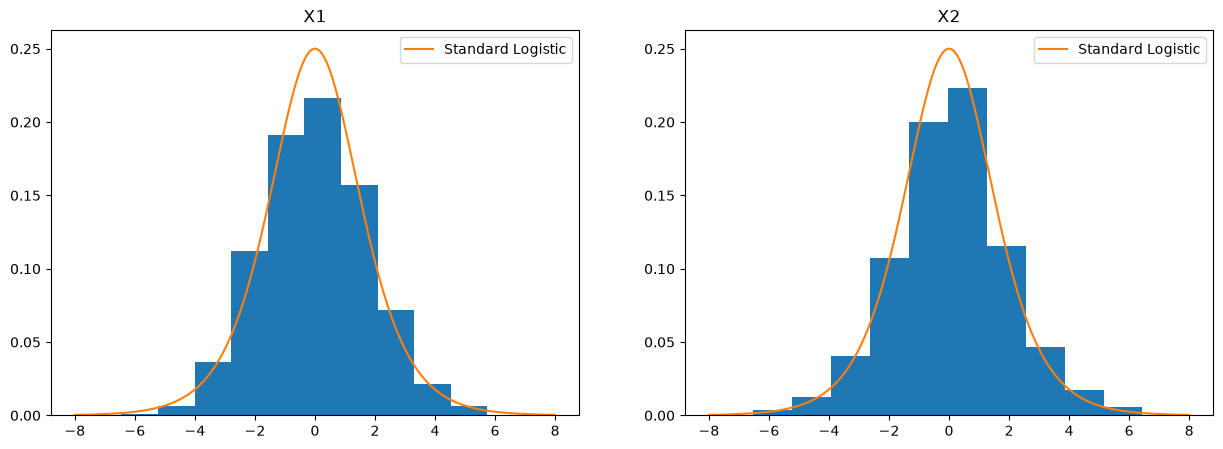

In [21]:
# Standard logistic PDF
x = np.linspace(-8, 8, 500)
pdf = np.exp(-x) / (1 + np.exp(-x))**2

_, axes = plt.subplots(1, 2, figsize=(15,5))

axes[0].hist(Xtilde[:,0], density=True)
axes[0].plot(x, pdf, label="Standard Logistic")
axes[0].legend()
axes[0].set_title('X1')

axes[1].hist(Xtilde[:,1], density=True)
axes[1].plot(x, pdf, label="Standard Logistic")
axes[1].legend()
axes[1].set_title('X2')

plt.show()

- $X_1 \perp X_2 \perp X_3 \sim \text{N} (0,1)$

In [22]:
n_runs = 50
res = [example2_normal() for _ in range(n_runs)]
res = np.array(res)

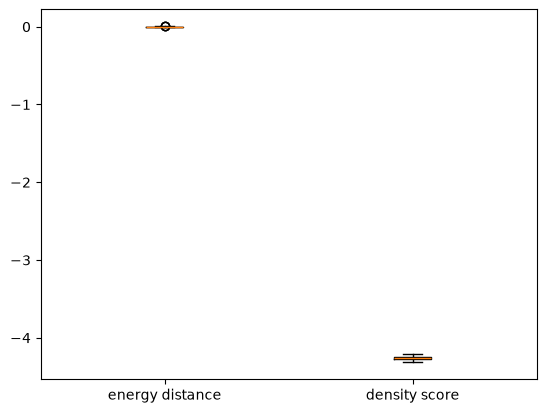

In [23]:
plt.boxplot(res, tick_labels=['energy distance', 'density score'])
plt.show()

In [24]:
n = 2000
U = torch.rand(n, 3)
X = torch.distributions.Normal(0, 1).icdf(U)
mg = MissingnessGenerator(U)
M = torch.ones_like(X, device=X.device)
M[:,:2] = mg.example2(U[:,0], U[:, 1])
gmm = GaussianMixtureMAR(k_range=(0, 20))
gmm.fit(X, M)
Xtilde = gmm.sample(n)[0]

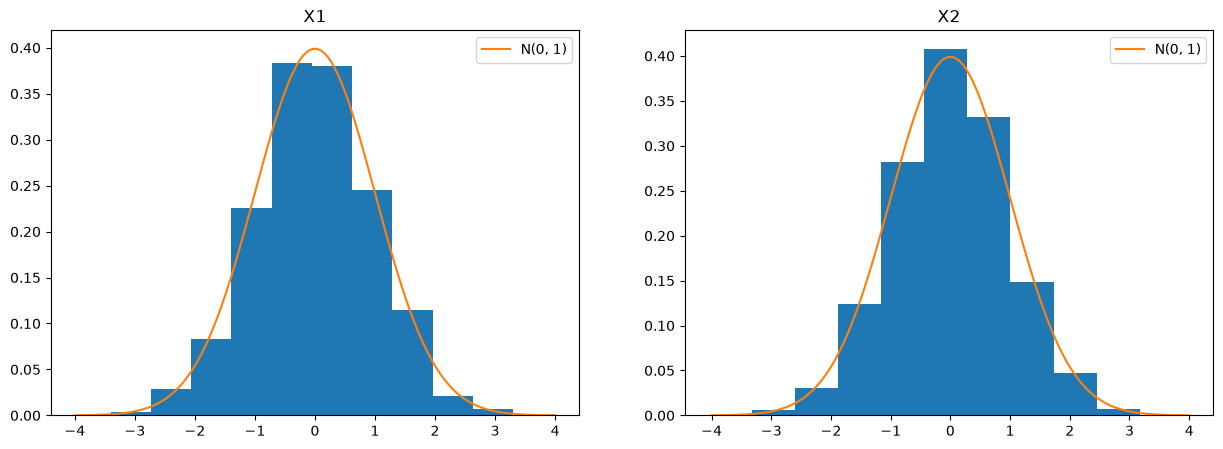

In [25]:
x = np.linspace(-4, 4, 500)

_, axes = plt.subplots(1, 2, figsize=(15,5))

axes[0].hist(Xtilde[:,0], density=True)
axes[0].plot(x, norm.pdf(x), label="N(0, 1)")
axes[0].legend()
axes[0].set_title('X1')

axes[1].hist(Xtilde[:,1], density=True)
axes[1].plot(x, norm.pdf(x), label="N(0, 1)")
axes[1].legend()
axes[1].set_title('X2')

plt.show()

# Impute $p_n(x^{(\bar m)} \mid x^{(m)})$

find the posterior mixture measure after observing $x^{(m)}$

$$
P(K = k \mid x^{(m)}) = \frac{P(x^{m} \mid K=k) \pi_k}{\sum_{j} P(x^{m} \mid K=j) \pi_j}
$$

$$
P(x^{(\bar m)} \mid x^{(m)}) = \sum_k P(K=k \mid x^{(m)}) P(x^{\bar m} \mid x^{(m)}, k) = \sum_k P(K=k \mid x^{(m)}) P(x^{\bar m} \mid k)
$$

In [26]:
U = torch.rand(n, 3)
X = torch.special.logit(U)
mg = MissingnessGenerator(U)
M = torch.ones_like(X, device=X.device)
M[:,:2] = mg.example2(U[:,0], U[:, 1])
Xtest = torch.special.logit(torch.rand(n, 3))
gmm = GaussianMixtureMAR(k_range=(1,20))
gmm.fit(X, M)

In [27]:
est_ed = [energy_distance(gmm.sample(n)[0], torch.special.logit(torch.rand(n, 3))) for _ in range(20)]
imp_ed = [energy_distance(gmm.impute(X, M), torch.special.logit(torch.rand(n, 3))) for _ in range(20)]

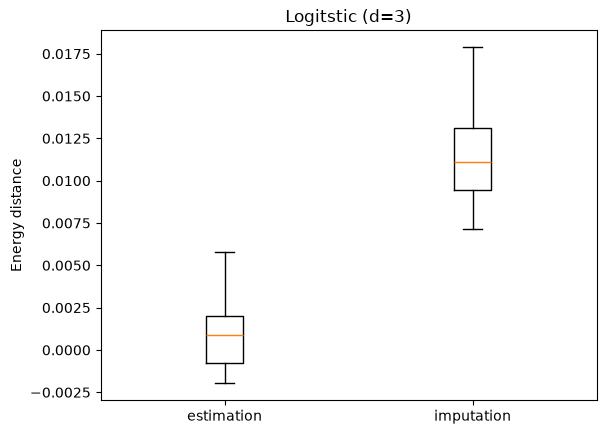

In [28]:
plt.boxplot([est_ed, imp_ed],
            tick_labels=["estimation", "imputation"])
plt.ylabel("Energy distance")
plt.title('Logitstic (d=3)')
plt.show()